In [1]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import sys
sys.path.append('/Users/Simon/GIT/GPlatesClassStruggle/')
from reconstruction_classes import *
from ptt import separate_ridge_transform_segments

import plate_driver as pdriver

%load_ext autoreload
%autoreload 2

M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')

Mu2016 = ReconstructionModel('Muller++2016')
Mu2016.add_rotation_model('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS.rot')
Mu2016.add_static_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_GPlates_PresentDay_StaticPlatePolygons_2015_v1.gpmlz')
Mu2016.add_dynamic_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS_PlateBoundaries.gpmlz')
Mu2016.add_dynamic_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS_Topology_BuildingBlocks.gpmlz')


In [52]:
delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}
#forces = {'ridge_push':1}

    
results = []    

reconstruction_time = 0
target_plate_id = 301
    
snapshot = M2016.plate_snapshot(reconstruction_time)

forces = {'ridge_push':1}
result_rp = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id,reconstruction_time, delta_time, forces)
    
forces = {'slab_pull':1}
result_sp = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time, forces)
        
forces = {'slab_suction':1}
result_ss = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time, forces)

forces = {'slab_pull':1,'slab_suction':1}
result_st = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time, forces)




In [18]:
#print result_rp[3],result_rp[5]
     
tmp = result_rp[3]
print tmp.get_euler_pole_and_angle()[0].to_lat_lon()

(30.666693809199415, 133.24388355236766)


(rot = (pole = (lat: 1.99334, lon: 170.749) (which is antipodal to (lat: -1.99334, lon: -9.25092)); angle = 0.0809174 deg))


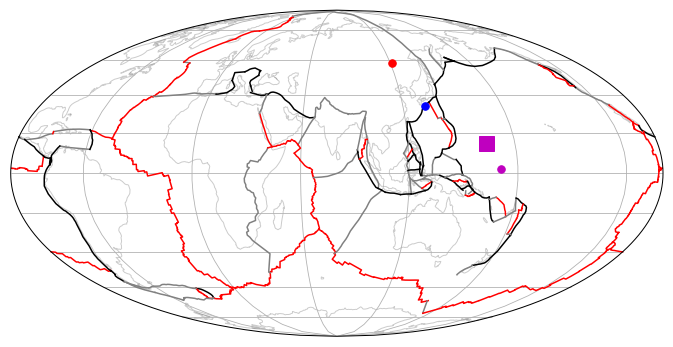

In [61]:
plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Mollweide(80,0))

for boundary in snapshot.resolved_topological_sections:
    shared_sub_segments = boundary.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if shared_sub_segment.get_resolved_feature().get_geometry() is not None:
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                boundary_color = 'black'
            elif shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_mid_ocean_ridge:
                boundary_color = 'red'
            else:
                boundary_color = 'gray'
            ax.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                    shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],
                    transform=ccrs.Geodetic(), color=boundary_color)

ax.plot(result_rp[3].get_euler_pole_and_angle()[0].to_lat_lon()[1],
        result_rp[3].get_euler_pole_and_angle()[0].to_lat_lon()[0], 
        'b.', markersize=15, transform=ccrs.PlateCarree())

ax.plot(result_sp[3].get_euler_pole_and_angle()[0].to_lat_lon()[1],
        result_sp[3].get_euler_pole_and_angle()[0].to_lat_lon()[0], 
        'r.', markersize=15, transform=ccrs.PlateCarree())

ax.plot(result_ss[3].get_euler_pole_and_angle()[0].to_lat_lon()[1],
        result_ss[3].get_euler_pole_and_angle()[0].to_lat_lon()[0], 
        'm.', markersize=15, transform=ccrs.PlateCarree())

ax.plot(result_st[3].get_euler_pole_and_angle()[0].to_lat_lon()[1],
        result_st[3].get_euler_pole_and_angle()[0].to_lat_lon()[0], 
        'ms', markersize=15, transform=ccrs.PlateCarree())

print result_ss[3]

ax.set_global()
ax.coastlines(alpha=0.2)
ax.gridlines()
#plt.legend()
plt.show()
